In [84]:
#import the necessary frameworks
import numpy as np
import pandas as pd

In [86]:
#load the dataset
german_credit = r"C:\Users\USER\Downloads\german_credit_data.xlsx"
df = pd.read_excel(german_credit)

In [88]:
#read the dataset
df.head(10)

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad
5,35,male,1,free,NaN,NaN,9055,36,education,good
6,53,male,2,own,quite rich,NaN,2835,24,furniture/equipment,good
7,35,male,3,rent,little,moderate,6948,36,car,good
8,61,male,1,own,rich,NaN,3059,12,radio/TV,good
9,28,male,3,own,little,moderate,5234,30,car,bad


In [90]:
#Initial Data Analysis (IDA)
#1. shape of the data
df.shape

(1000, 10)

In [92]:
#2. number of columns
df.columns

Index(['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account',
       'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='str')

In [94]:
#3. data types
df.dtypes

Age                 int64
Sex                   str
Job                 int64
Housing               str
Saving accounts       str
Checking account      str
Credit amount       int64
Duration            int64
Purpose               str
Risk                  str
dtype: object

In [96]:
#4. completeness of the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Age               1000 non-null   int64
 1   Sex               1000 non-null   str  
 2   Job               1000 non-null   int64
 3   Housing           1000 non-null   str  
 4   Saving accounts   817 non-null    str  
 5   Checking account  606 non-null    str  
 6   Credit amount     1000 non-null   int64
 7   Duration          1000 non-null   int64
 8   Purpose           1000 non-null   str  
 9   Risk              1000 non-null   str  
dtypes: int64(4), str(6)
memory usage: 107.3 KB


In [98]:
#5. Descriptive statistics of the columns
df.describe()

,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


In [17]:
df.describe(include='all')

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
count,1000.000000,1000,1000.000000,1000,817,606,1000.000000,1000.000000,1000,1000
unique,NaN,2,NaN,3,4,3,NaN,NaN,8,2
top,NaN,male,NaN,own,little,little,NaN,NaN,car,good
freq,NaN,690,NaN,713,603,274,NaN,NaN,337,700
mean,35.546000,NaN,1.904000,NaN,NaN,NaN,3271.258000,20.903000,NaN,NaN
std,11.375469,NaN,0.653614,NaN,NaN,NaN,2822.736876,12.058814,NaN,NaN
min,19.000000,NaN,0.000000,NaN,NaN,NaN,250.000000,4.000000,NaN,NaN
25%,27.000000,NaN,2.000000,NaN,NaN,NaN,1365.500000,12.000000,NaN,NaN
50%,33.000000,NaN,2.000000,NaN,NaN,NaN,2319.500000,18.000000,NaN,NaN
75%,42.000000,NaN,2.000000,NaN,NaN,NaN,3972.250000,24.000000,NaN,NaN


In [100]:
#6. Missing values
df.isnull().sum()


Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64

In [102]:
#7. Duplicates
df.duplicated().sum()

np.int64(0)

In [104]:
# 8. count unique values in each column
for col in df.columns:
    print(f"{col}:{df[col].nunique()}unique values")

Age:53unique values
Sex:2unique values
Job:4unique values
Housing:3unique values
Saving accounts:4unique values
Checking account:3unique values
Credit amount:921unique values
Duration:33unique values
Purpose:8unique values
Risk:2unique values


In [106]:
#Data Wrangling
#Data Cleaning
#Data Preprocessing
#1. Handling missing values
df['Saving accounts'] = (df['Saving accounts'].fillna("Unknown"))
df['Checking account'] = (df['Checking account'].fillna("Unknown"))
df.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,Unknown,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,Unknown,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


In [108]:
#2. Convert categorical values into categorical data types
df['Sex'] = df['Sex'].astype("category")
df['Housing'] = df['Housing'].astype("category")
df.dtypes

Age                    int64
Sex                 category
Job                    int64
Housing             category
Saving accounts          str
Checking account         str
Credit amount          int64
Duration               int64
Purpose                  str
Risk                     str
dtype: object

In [110]:
#3.Data Normolization
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df['Credit amount_normalized'] = scaler.fit_transform(df[['Credit amount']])
df.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk,Credit amount_normalized
0,67,male,2,own,Unknown,little,1169,6,radio/TV,good,0.050567
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad,0.313690
2,49,male,1,own,little,Unknown,2096,12,education,good,0.101574
3,45,male,2,free,little,little,7882,42,furniture/equipment,good,0.419941
4,53,male,2,free,little,little,4870,24,car,bad,0.254209


In [112]:
#4. Binning
df["Age_groups"] = pd.cut(
    df["Age"],
    bins=[18, 31, 41, 51, 61, float("inf")],
    labels=["Youth", "Young Adult", "Middle Age", "Oldie", "Senior"],
    right=False
)
df.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk,Credit amount_normalized,Age_groups
0,67,male,2,own,Unknown,little,1169,6,radio/TV,good,0.050567,Senior
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad,0.313690,Youth
2,49,male,1,own,little,Unknown,2096,12,education,good,0.101574,Middle Age
3,45,male,2,free,little,little,7882,42,furniture/equipment,good,0.419941,Middle Age
4,53,male,2,free,little,little,4870,24,car,bad,0.254209,Oldie


In [118]:
#5. Encode categorigal variables #0, 1
df_encode = pd.get_dummies(df, drop_first=True)

In [122]:
#Exploratory Data Analysis (EDA)
#credit amount stats
print("Credit amount statistics:\n", df['Credit amount'].describe())

Credit amount statistics:
 count     1000.000000
mean      3271.258000
std       2822.736876
min        250.000000
25%       1365.500000
50%       2319.500000
75%       3972.250000
max      18424.000000
Name: Credit amount, dtype: float64


In [124]:
#Analysis Credit amount by Risk
print("Mean Credit amount by Risk:\n", df.groupby('Risk')['Credit amount'].mean())

Mean Credit amount by Risk:
 Risk
bad     3938.126667
good    2985.457143
Name: Credit amount, dtype: float64


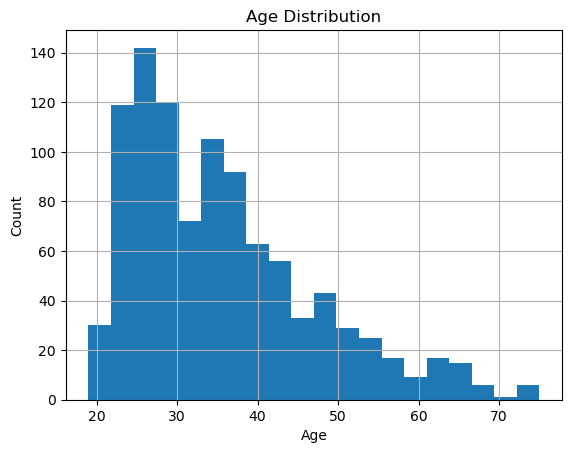

In [128]:
#Visualize the age distribution
import matplotlib.pyplot as plt
import seaborn as sns
df['Age'].hist(bins=20)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

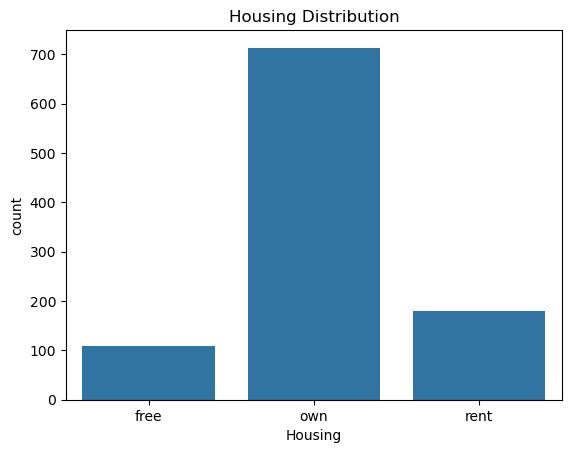

In [130]:
#Analysis of Housing Categoreis
sns.countplot(x='Housing', data=df)
plt.title("Housing Distribution")
plt.show()

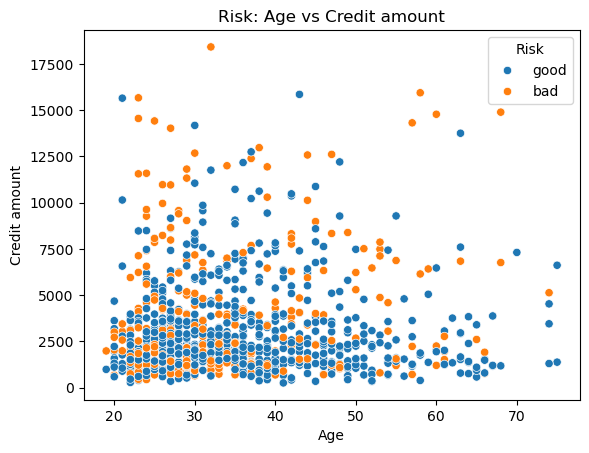

In [132]:
#Analysis of the relationship between Age and Credit Amount
sns.scatterplot(
    x='Age',
    y='Credit amount',
    hue='Risk',
    data=df)
plt.title("Risk: Age vs Credit amount")
plt.show()
    

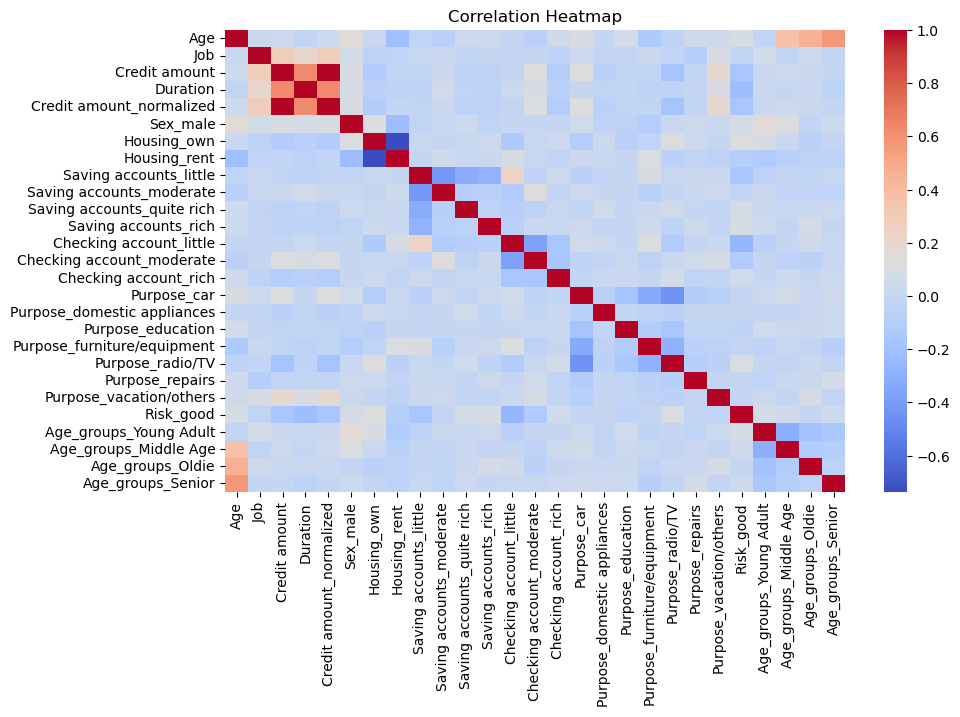

In [140]:
#Correlation of encoded variables
plt.figure(figsize=(10,6))
sns.heatmap(df_encode.corr(),cmap='coolwarm', annot=False)
plt.title("Correlation Heatmap")
plt.show()